# Project PT1: Human Activity Recognition (HAR)
**Course:** Machine Learning  
**Dataset:** WISDM Activity Prediction v1.1  
**Student Name:** Mahsa Ghorbani

---

### 📖 Overview
In this project, we analyze raw smartphone accelerometer data to recognize human activities. The dataset contains 1,098,208 records from 36 users performing 6 activities (Walking, Jogging, Upstairs, Downstairs, Sitting, Standing).

The project is divided into five main parts:
1. **Data Loading & Cleaning:** Parsing the raw text file and handling invalid records.
2. **Exploratory Data Analysis (EDA):** Visualizing signals and finding statistical differences between activities.
3. **Windowing:** Splitting the continuous time-series data into smaller fixed-size windows.
4. **Subject-wise Split:** Dividing data based on users to prevent data leakage.
5. **Baseline Modeling:** Training simple models to create a benchmark for future improvements.

For the interactive visualization, a separate Streamlit dashboard (`dashboard.py`) has been created.

## Step 1: Environment Setup
**Goal:** Prepare the Python environment for data analysis and visualization.

- **Imports:** Loading necessary libraries (pandas for data, matplotlib/seaborn for plots, numpy for math).
- **Settings:** Configuring pandas to show all columns and round floats to 4 decimals. Setting default plot sizes for better readability.
- **Path Check:** Defining the dataset path and verifying the file exists to prevent "File Not Found" errors later.

In [1]:
# Cell 1: Imports & Settings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

# Plot settings
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100
sns.set_style('whitegrid')

# Dataset path (same folder as notebook)
DATA_PATH = 'WISDM_ar_v1.1_raw.txt'

print('Libraries imported successfully')
print(f'pandas  : {pd.__version__}')
print(f'numpy   : {np.__version__}')
print(f'seaborn : {sns.__version__}')
print(f'File exists? {os.path.exists(DATA_PATH)}')

Libraries imported successfully
pandas  : 2.3.3
numpy   : 1.26.4
seaborn : 0.13.2
File exists? True


In [2]:
# Cell 2: Load & Parse - handle extra trailing commas

records = []
invalid_lines = []

with open(DATA_PATH, 'r', encoding='utf-8', errors='ignore') as f:
    for line_no, line in enumerate(f, start=1):
        line = line.strip()
        if not line:
            continue
        # Split by ';' first (handles concatenated records)
        segments = line.split(';')
        for seg in segments:
            seg = seg.strip().strip(',').strip()  # remove extra commas
            if not seg:
                continue
            parts = seg.split(',')
            # Remove empty fields from trailing commas
            parts = [p.strip() for p in parts if p.strip() != '']
            if len(parts) == 6:
                records.append(parts)
            else:
                invalid_lines.append((line_no, seg))

print(f'Total valid records : {len(records):,}')
print(f'Invalid segments    : {len(invalid_lines):,}')

# Build DataFrame
df = pd.DataFrame(records, columns=['user', 'activity', 'timestamp', 'x', 'y', 'z'])

df['user'] = df['user'].astype(int)
df['timestamp'] = pd.to_numeric(df['timestamp'], errors='coerce')
df['x'] = pd.to_numeric(df['x'], errors='coerce')
df['y'] = pd.to_numeric(df['y'], errors='coerce')
df['z'] = pd.to_numeric(df['z'], errors='coerce')

print(f'\nDataFrame shape: {df.shape}')
print(f'\nUnique users     : {df["user"].nunique()}')
print(f'Unique activities: {df["activity"].nunique()}')
print(f'Activities       : {sorted(df["activity"].unique())}')
print(f'\nNaN counts per column:')
print(df.isna().sum())

print('\nFirst 3 rows:')
display(df.head(3))

print('\nLast 3 rows:')
display(df.tail(3))

if invalid_lines:
    print(f'\nSample invalid segments (first 10):')
    for ln, content in invalid_lines[:10]:
        print(f'  line {ln}: {content[:150]}')

Total valid records : 1,098,208
Invalid segments    : 1

DataFrame shape: (1098208, 6)

Unique users     : 36
Unique activities: 6
Activities       : ['Downstairs', 'Jogging', 'Sitting', 'Standing', 'Upstairs', 'Walking']

NaN counts per column:
user         0
activity     0
timestamp    0
x            0
y            0
z            0
dtype: int64

First 3 rows:


,user,activity,timestamp,x,y,z
0,33,Jogging,49105962326000,-0.6946,12.6805,0.5040
1,33,Jogging,49106062271000,5.0123,11.2640,0.9534
2,33,Jogging,49106112167000,4.9033,10.8827,-0.0817



Last 3 rows:


,user,activity,timestamp,x,y,z
1098205,19,Sitting,131623411592000,9.0800,-1.3800,1.6900
1098206,19,Sitting,131623491487000,9.0000,-1.4600,1.7300
1098207,19,Sitting,131623531465000,8.8800,-1.3300,1.6100



Sample invalid segments (first 10):
  line 343420: 11,Walking,1867172313000,4.4,4.4


In [3]:
# Cell 3: Data Structure Overview (Section 1)

print('=' * 60)
print('DATA OVERVIEW')
print('=' * 60)
print(f'Total records     : {len(df):,}')
print(f'Unique users      : {df["user"].nunique()}')
print(f'Unique activities : {df["activity"].nunique()}')
print(f'Activities        : {sorted(df["activity"].unique())}')
print(f'Users             : {sorted(df["user"].unique())}')

print('\n' + '=' * 60)
print('ACTIVITY DISTRIBUTION')
print('=' * 60)
activity_counts = df['activity'].value_counts()
activity_pct = df['activity'].value_counts(normalize=True) * 100
activity_df = pd.DataFrame({
    'Count': activity_counts,
    'Percentage (%)': activity_pct.round(2)
})
print(activity_df)

print('\n' + '=' * 60)
print('RECORDS PER USER')
print('=' * 60)
user_counts = df['user'].value_counts().sort_index()
print(user_counts)

print('\n' + '=' * 60)
print('ACTIVITY x USER MATRIX (how many records per user per activity)')
print('=' * 60)
pivot = df.pivot_table(index='user', columns='activity', values='timestamp', aggfunc='count', fill_value=0)
display(pivot)

print('\n' + '=' * 60)
print('BASIC QUESTIONS')
print('=' * 60)
print(f'Most frequent activity  : {activity_counts.idxmax()} ({activity_counts.max():,} records)')
print(f'Least frequent activity : {activity_counts.idxmin()} ({activity_counts.min():,} records)')
print(f'Max records by a user   : {user_counts.max():,} (user {user_counts.idxmax()})')
print(f'Min records by a user   : {user_counts.min():,} (user {user_counts.idxmin()})')
print(f'Are activity counts equal? {activity_counts.nunique() == 1}')
print(f'Are user counts equal?     {user_counts.nunique() == 1}')

DATA OVERVIEW
Total records     : 1,098,208
Unique users      : 36
Unique activities : 6
Activities        : ['Downstairs', 'Jogging', 'Sitting', 'Standing', 'Upstairs', 'Walking']
Users             : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]

ACTIVITY DISTRIBUTION
             Count  Percentage (%)
activity                          
Walking     424399         38.6400
Jogging     342179         31.1600
Upstairs    122869         11.1900
Downstairs  100427          9.1400
Sitting      59939          5.4600
Standing     48395          4.4100

RECORDS PER USER
user
1     29978
2     23525
3     35161
4     11371
5     28510
6     29704
7     30967
8     41188
9     12923
10    34883
11    31658
12    32641
13    37093
14    38192
15    28155
16    20470
17    22020
18    32812
19    45383
20    56632
21    35436
22    22310
23    25673
24    25736
25    13468
26    32578
27    34959
28    21358
2

activity,Downstairs,Jogging,Sitting,Standing,Upstairs,Walking
user,,,,,,
1,2941,11056,0,0,3120,12861
2,0,11786,0,0,0,11739
3,3326,11018,1609,2824,3411,12973
4,1763,895,1257,0,1377,6079
5,3281,6405,1664,1515,3387,12258
6,1433,11818,1679,709,1666,12399
7,2257,9183,2529,2364,3601,11033
8,3346,10313,2699,3269,4453,17108
9,0,0,0,0,0,12923



BASIC QUESTIONS
Most frequent activity  : Walking (424,399 records)
Least frequent activity : Standing (48,395 records)
Max records by a user   : 56,632 (user 20)
Min records by a user   : 11,371 (user 4)
Are activity counts equal? False
Are user counts equal?     False


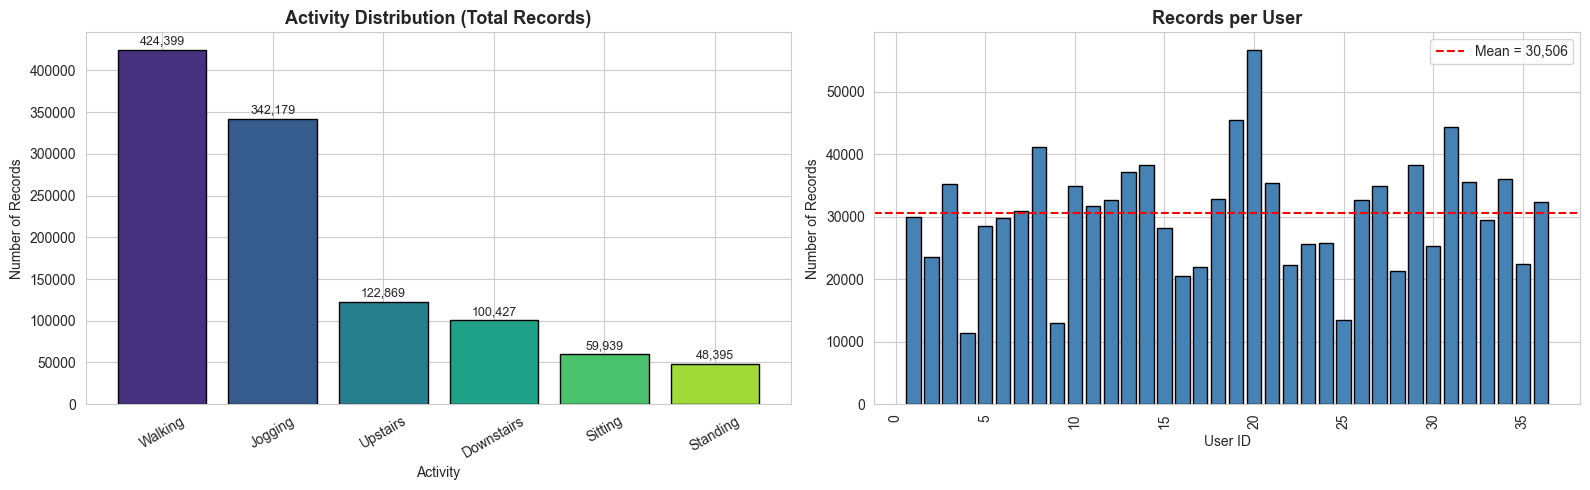

Activity distribution:
activity
Walking       424399
Jogging       342179
Upstairs      122869
Downstairs    100427
Sitting        59939
Standing       48395
Name: count, dtype: int64

Mean per user  : 30,506
Std per user   : 9,284
Min / Max      : 11,371 / 56,632


In [4]:
# Cell 4: Distribution Plots (Section 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- Plot 1: Activity distribution ---
activity_counts = df['activity'].value_counts()
colors = sns.color_palette('viridis', len(activity_counts))
bars = axes[0].bar(activity_counts.index, activity_counts.values, color=colors, edgecolor='black')
axes[0].set_title('Activity Distribution (Total Records)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Activity')
axes[0].set_ylabel('Number of Records')
axes[0].tick_params(axis='x', rotation=30)

# Add count labels on top of bars
for bar, val in zip(bars, activity_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3000,
                 f'{val:,}', ha='center', va='bottom', fontsize=9)

# --- Plot 2: Records per user ---
user_counts = df['user'].value_counts().sort_index()
bars2 = axes[1].bar(user_counts.index, user_counts.values, color='steelblue', edgecolor='black')
axes[1].set_title('Records per User', fontsize=13, fontweight='bold')
axes[1].set_xlabel('User ID')
axes[1].set_ylabel('Number of Records')
axes[1].axhline(user_counts.mean(), color='red', linestyle='--', label=f'Mean = {user_counts.mean():,.0f}')
axes[1].legend()
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

# Summary stats
print('Activity distribution:')
print(activity_counts)
print(f'\nMean per user  : {user_counts.mean():,.0f}')
print(f'Std per user   : {user_counts.std():,.0f}')
print(f'Min / Max      : {user_counts.min():,} / {user_counts.max():,}')

In [5]:
# Cell 5: Windowing (Section 3)

WINDOW_SIZE = 51
STEP_SIZE = 26

def create_windows(data, window_size=WINDOW_SIZE, step=STEP_SIZE):
    """Create sliding windows per (user, activity) group."""
    windows = []
    
    # Group by (user, activity) to prevent crossing boundaries
    grouped = data.groupby(['user', 'activity'], sort=False)
    
    for (user, activity), group in grouped:
        # Sort by timestamp to ensure temporal order
        group = group.sort_values('timestamp').reset_index(drop=True)
        signals = group[['x', 'y', 'z']].values
        n = len(signals)
        
        if n < window_size:
            continue  # skip groups too short for one window
        
        # Create sliding windows
        for start in range(0, n - window_size + 1, step):
            end = start + window_size
            window = signals[start:end]
            windows.append({
                'user': user,
                'activity': activity,
                'start_idx': start,
                'data': window
            })
    
    return windows

print('Creating windows...')
windows = create_windows(df)
print(f'Total windows created: {len(windows):,}')

# Build summary DataFrame
window_df = pd.DataFrame([{
    'user': w['user'],
    'activity': w['activity'],
    'start_idx': w['start_idx']
} for w in windows])

print('\n' + '=' * 60)
print('WINDOWS PER ACTIVITY')
print('=' * 60)
win_per_activity = window_df['activity'].value_counts()
print(win_per_activity)

print('\n' + '=' * 60)
print('WINDOWS PER USER (top 10)')
print('=' * 60)
print(window_df['user'].value_counts().sort_index().head(10))

print('\n' + '=' * 60)
print('COMPARISON: RAW vs WINDOWS')
print('=' * 60)
print(f'Raw records       : {len(df):,}')
print(f'Total windows     : {len(windows):,}')
print(f'Window size       : {WINDOW_SIZE}')
print(f'Step size         : {STEP_SIZE}')
print(f'Overlap           : {WINDOW_SIZE - STEP_SIZE} samples ({100*(WINDOW_SIZE-STEP_SIZE)/WINDOW_SIZE:.0f}%)')
print(f'Approx window duration: {WINDOW_SIZE/20:.2f} sec (at 20 Hz)')

Creating windows...
Total windows created: 41,986

WINDOWS PER ACTIVITY
activity
Walking       16272
Jogging       13119
Upstairs       4682
Downstairs     3814
Sitting        2271
Standing       1828
Name: count, dtype: int64

WINDOWS PER USER (top 10)
user
1     1148
2      902
3     1343
4      430
5     1089
6     1134
7     1182
8     1575
9      496
10    1334
Name: count, dtype: int64

COMPARISON: RAW vs WINDOWS
Raw records       : 1,098,208
Total windows     : 41,986
Window size       : 51
Step size         : 26
Overlap           : 25 samples (49%)
Approx window duration: 2.55 sec (at 20 Hz)


In [6]:
# Cell 6: Subject-wise Split (Section 4)

from sklearn.model_selection import train_test_split

# Get unique users
all_users = sorted(df['user'].unique())
print(f'Total unique users: {len(all_users)}')

# Split users: 70% train, 15% val, 15% test
# First split: train vs (val + test)
train_users, temp_users = train_test_split(
    all_users, test_size=0.30, random_state=42
)
# Second split: val vs test (half-half of remaining 30%)
val_users, test_users = train_test_split(
    temp_users, test_size=0.50, random_state=42
)

train_users = sorted(train_users)
val_users = sorted(val_users)
test_users = sorted(test_users)

print(f'\nTrain users ({len(train_users)}): {train_users}')
print(f'Val users   ({len(val_users)}): {val_users}')
print(f'Test users  ({len(test_users)}): {test_users}')

# Verify no overlap
assert len(set(train_users) & set(val_users)) == 0, 'Overlap train/val!'
assert len(set(train_users) & set(test_users)) == 0, 'Overlap train/test!'
assert len(set(val_users) & set(test_users)) == 0, 'Overlap val/test!'
print('\n✅ No user overlap between splits')

# Assign windows to splits based on user
window_df['split'] = window_df['user'].apply(
    lambda u: 'train' if u in train_users else ('val' if u in val_users else 'test')
)

print('\n' + '=' * 60)
print('WINDOWS PER SPLIT')
print('=' * 60)
split_counts = window_df['split'].value_counts()
print(split_counts)

print('\n' + '=' * 60)
print('ACTIVITY DISTRIBUTION PER SPLIT')
print('=' * 60)
activity_per_split = pd.crosstab(window_df['split'], window_df['activity'])
display(activity_per_split)

print('\n' + '=' * 60)
print('PERCENTAGE OF EACH ACTIVITY PER SPLIT')
print('=' * 60)
activity_pct_split = pd.crosstab(window_df['split'], window_df['activity'], normalize='index') * 100
display(activity_pct_split.round(2))

# Verify: each window's user belongs to only one split
print('\n' + '=' * 60)
print('VERIFICATION: users per split')
print('=' * 60)
for split in ['train', 'val', 'test']:
    users_in_split = sorted(window_df[window_df['split'] == split]['user'].unique())
    print(f'{split:5s}: {len(users_in_split)} users -> {users_in_split}')

Total unique users: 36

Train users (25): [1, 2, 3, 4, 5, 6, 7, 8, 11, 12, 15, 16, 19, 20, 21, 23, 24, 25, 26, 28, 29, 30, 33, 34, 35]
Val users   (5): [9, 13, 17, 22, 31]
Test users  (6): [10, 14, 18, 27, 32, 36]

✅ No user overlap between splits

WINDOWS PER SPLIT
split
train    28706
test      7978
val       5302
Name: count, dtype: int64

ACTIVITY DISTRIBUTION PER SPLIT


activity,Downstairs,Jogging,Sitting,Standing,Upstairs,Walking
split,,,,,,
test,725,2826,345,333,1045,2704
train,2498,8932,1801,1334,2857,11284
val,591,1361,125,161,780,2284



PERCENTAGE OF EACH ACTIVITY PER SPLIT


activity,Downstairs,Jogging,Sitting,Standing,Upstairs,Walking
split,,,,,,
test,9.0900,35.4200,4.3200,4.1700,13.1000,33.8900
train,8.7000,31.1200,6.2700,4.6500,9.9500,39.3100
val,11.1500,25.6700,2.3600,3.0400,14.7100,43.0800



VERIFICATION: users per split
train: 25 users -> [1, 2, 3, 4, 5, 6, 7, 8, 11, 12, 15, 16, 19, 20, 21, 23, 24, 25, 26, 28, 29, 30, 33, 34, 35]
val  : 5 users -> [9, 13, 17, 22, 31]
test : 6 users -> [10, 14, 18, 27, 32, 36]


In [7]:
# Cell 7: Baseline Models (Section 5)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import time

# Separate data by splits based on the window_df tags
train_windows = window_df[window_df['split'] == 'train']
val_windows   = window_df[window_df['split'] == 'val']
test_windows  = window_df[window_df['split'] == 'test']

# Build X (flattened 51x3 = 153 features) and y (labels)
def build_Xy(windows_subset, windows_list):
    idx_map = {i: w for i, w in enumerate(windows_list)}
    
    X = []
    y = []
    
    for _, row in windows_subset.iterrows():
        # Find matching window by (user, activity, start_idx)
        # Use a simpler approach: map through the windows_list directly
        pass
    
    return X, y

# Better approach: build directly from windows list
def split_Xy(windows, target_users):
    X, y = [], []
    for w in windows:
        if w['user'] in target_users:
            # Flatten the (51, 3) matrix into a 1D array of 153 features
            X.append(w['data'].flatten())
            y.append(w['activity'])
    return np.array(X), np.array(y)

print('Preparing datasets...')
X_train, y_train = split_Xy(windows, set(train_users))
X_val, y_val     = split_Xy(windows, set(val_users))
X_test, y_test   = split_Xy(windows, set(test_users))

print(f'X_train: {X_train.shape}, y_train: {y_train.shape}')
print(f'X_val  : {X_val.shape}, y_val: {y_val.shape}')
print(f'X_test : {X_test.shape}, y_test: {y_test.shape}')

# ============================================
# Model 1: Majority Class Baseline
# ============================================
print('\n' + '='*60)
print('MODEL 1: Majority Class Baseline')
print('='*60)

dummy = DummyClassifier(strategy='most_frequent', random_state=42)
dummy.fit(X_train, y_train)

y_pred_dummy = dummy.predict(X_test)
acc_dummy = accuracy_score(y_test, y_pred_dummy)
macro_f1_dummy = f1_score(y_test, y_pred_dummy, average='macro')

print(f'Accuracy  : {acc_dummy:.4f}')
print(f'Macro-F1  : {macro_f1_dummy:.4f}')

# ============================================
# Model 2: Decision Tree
# ============================================
print('\n' + '='*60)
print('MODEL 2: Decision Tree')
print('='*60)

dt = DecisionTreeClassifier(max_depth=10, random_state=42)
t0 = time.time()
dt.fit(X_train, y_train)
print(f'Training time: {time.time() - t0:.2f}s')

y_pred_dt = dt.predict(X_test)
acc_dt = accuracy_score(y_test, y_pred_dt)
macro_f1_dt = f1_score(y_test, y_pred_dt, average='macro')

print(f'Accuracy  : {acc_dt:.4f}')
print(f'Macro-F1  : {macro_f1_dt:.4f}')

# ============================================
# Model 3: Logistic Regression
# ============================================
print('\n' + '='*60)
print('MODEL 3: Logistic Regression')
print('='*60)

lr = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1)
t0 = time.time()
lr.fit(X_train, y_train)
print(f'Training time: {time.time() - t0:.2f}s')

y_pred_lr = lr.predict(X_test)
acc_lr = accuracy_score(y_test, y_pred_lr)
macro_f1_lr = f1_score(y_test, y_pred_lr, average='macro')

print(f'Accuracy  : {acc_lr:.4f}')
print(f'Macro-F1  : {macro_f1_lr:.4f}')

# ============================================
# Summary
# ============================================
print('\n' + '='*60)
print('SUMMARY')
print('='*60)
print(f'{"Model":<25} {"Accuracy":>10} {"Macro-F1":>10}')
print('-'*60)
print(f'{"Majority Class":<25} {acc_dummy:>10.4f} {macro_f1_dummy:>10.4f}')
print(f'{"Decision Tree":<25} {acc_dt:>10.4f} {macro_f1_dt:>10.4f}')
print(f'{"Logistic Regression":<25} {acc_lr:>10.4f} {macro_f1_lr:>10.4f}')

Preparing datasets...
X_train: (28706, 153), y_train: (28706,)
X_val  : (5302, 153), y_val: (5302,)
X_test : (7978, 153), y_test: (7978,)

MODEL 1: Majority Class Baseline
Accuracy  : 0.3389
Macro-F1  : 0.0844

MODEL 2: Decision Tree
Training time: 4.72s
Accuracy  : 0.6073
Macro-F1  : 0.4012

MODEL 3: Logistic Regression
Training time: 25.61s
Accuracy  : 0.4890
Macro-F1  : 0.3224

SUMMARY
Model                       Accuracy   Macro-F1
------------------------------------------------------------
Majority Class                0.3389     0.0844
Decision Tree                 0.6073     0.4012
Logistic Regression           0.4890     0.3224


DETAILED CLASSIFICATION REPORT (Decision Tree)
              precision    recall  f1-score   support

  Downstairs     0.1883    0.0400    0.0660       725
     Jogging     0.8821    0.6992    0.7801      2826
     Sitting     0.9850    0.7623    0.8595       345
    Standing     0.0000    0.0000    0.0000       333
    Upstairs     0.1245    0.0287    0.0467      1045
     Walking     0.5018    0.9419    0.6548      2704

    accuracy                         0.6073      7978
   macro avg     0.4470    0.4120    0.4012      7978
weighted avg     0.5586    0.6073    0.5475      7978



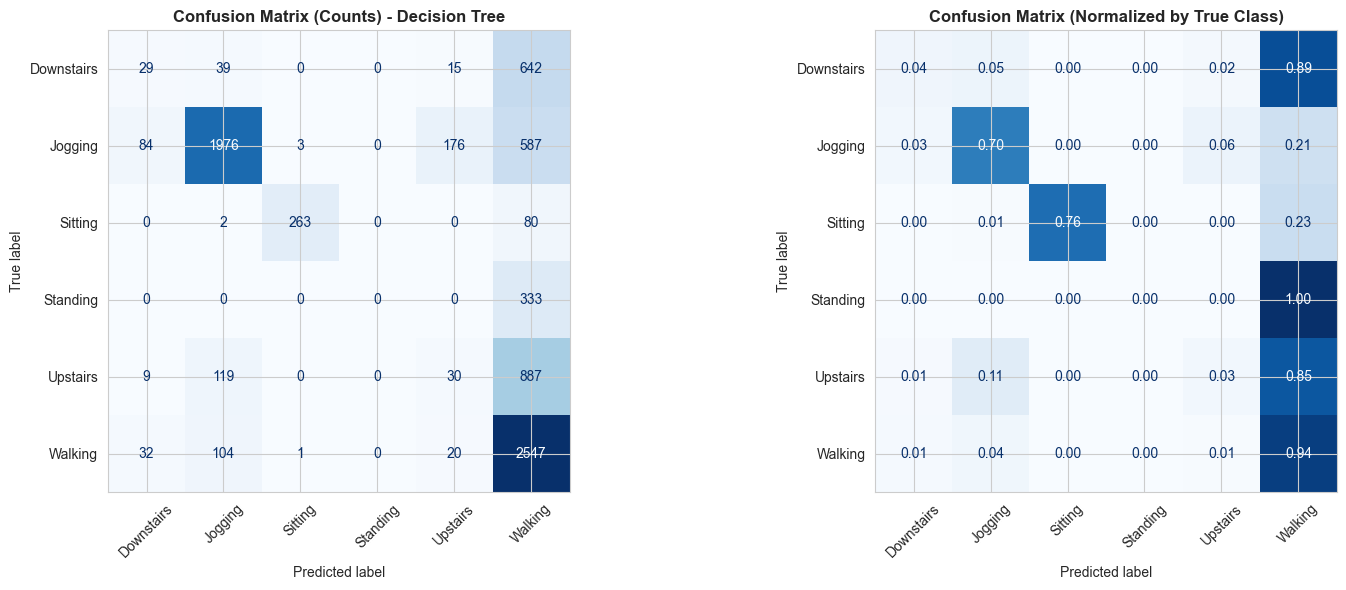


PER-CLASS METRICS
            Precision  Recall  F1-score  Support
Downstairs     0.1883  0.0400    0.0660      725
Jogging        0.8821  0.6992    0.7801     2826
Sitting        0.9850  0.7623    0.8595      345
Standing       0.0000  0.0000    0.0000      333
Upstairs       0.1245  0.0287    0.0467     1045
Walking        0.5018  0.9419    0.6548     2704

TOP CONFUSIONS (where model makes mistakes)
Downstairs   -> predicted as Jogging      :   39 times
Downstairs   -> predicted as Walking      :  642 times
Jogging      -> predicted as Downstairs   :   84 times
Jogging      -> predicted as Upstairs     :  176 times
Jogging      -> predicted as Walking      :  587 times
Sitting      -> predicted as Walking      :   80 times
Standing     -> predicted as Walking      :  333 times
Upstairs     -> predicted as Jogging      :  119 times
Upstairs     -> predicted as Walking      :  887 times
Walking      -> predicted as Downstairs   :   32 times
Walking      -> predicted as Jogging      :

In [8]:
# Cell 8: Confusion Matrix & Detailed Metrics

from sklearn.metrics import ConfusionMatrixDisplay

# Use Decision Tree (best model)
best_model = dt
best_pred = y_pred_dt

# Class order for consistent display
classes = sorted(df['activity'].unique())

# --- Detailed classification report ---
print('='*60)
print('DETAILED CLASSIFICATION REPORT (Decision Tree)')
print('='*60)
print(classification_report(y_test, best_pred, target_names=classes, digits=4))

# --- Confusion Matrix ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Raw counts
cm = confusion_matrix(y_test, best_pred, labels=classes)
disp1 = ConfusionMatrixDisplay(cm, display_labels=classes)
disp1.plot(ax=axes[0], cmap='Blues', values_format='d', colorbar=False)
axes[0].set_title('Confusion Matrix (Counts) - Decision Tree', fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

# Normalized (row-wise)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)
disp2 = ConfusionMatrixDisplay(cm_norm, display_labels=classes)
disp2.plot(ax=axes[1], cmap='Blues', values_format='.2f', colorbar=False)
axes[1].set_title('Confusion Matrix (Normalized by True Class)', fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# --- Per-class metrics table ---
print('\n' + '='*60)
print('PER-CLASS METRICS')
print('='*60)
metrics_df = pd.DataFrame({
    'Precision': precision_score(y_test, best_pred, average=None, labels=classes),
    'Recall'   : recall_score(y_test, best_pred, average=None, labels=classes),
    'F1-score' : f1_score(y_test, best_pred, average=None, labels=classes),
    'Support'  : [np.sum(y_test == c) for c in classes]
}, index=classes).round(4)
print(metrics_df)

# --- How often each activity is confused with another ---
print('\n' + '='*60)
print('TOP CONFUSIONS (where model makes mistakes)')
print('='*60)
for i, true_class in enumerate(classes):
    for j, pred_class in enumerate(classes):
        if i != j and cm[i, j] > 0:
            if cm[i, j] > 20:  # threshold to avoid clutter
                print(f'{true_class:12s} -> predicted as {pred_class:12s} : {cm[i, j]:>4d} times')

In [9]:
# Cell 9: Model Comparison Summary (Section 5)

results = pd.DataFrame({
    'Model'    : ['Majority Class', 'Logistic Regression', 'Decision Tree'],
    'Accuracy' : [acc_dummy, acc_lr, acc_dt],
    'Macro-F1' : [macro_f1_dummy, macro_f1_lr, macro_f1_dt],
    'Precision (macro)': [
        precision_score(y_test, y_pred_dummy, average='macro', zero_division=0),
        precision_score(y_test, y_pred_lr, average='macro', zero_division=0),
        precision_score(y_test, y_pred_dt, average='macro', zero_division=0)
    ],
    'Recall (macro)': [
        recall_score(y_test, y_pred_dummy, average='macro', zero_division=0),
        recall_score(y_test, y_pred_lr, average='macro', zero_division=0),
        recall_score(y_test, y_pred_dt, average='macro', zero_division=0)
    ]
}).round(4)

print('='*70)
print('FINAL MODEL COMPARISON')
print('='*70)
print(results.to_string(index=False))

# Improvement over baseline
print('\n' + '='*70)
print('IMPROVEMENT OVER MAJORITY CLASS')
print('='*70)
print(f'Decision Tree improves Accuracy by {(acc_dt - acc_dummy)*100:.1f}%')
print(f'Decision Tree improves Macro-F1 by {(macro_f1_dt - macro_f1_dummy)*100:.1f}%')

# Which classes are hardest?
print('\n' + '='*70)
print('DIFFICULTY RANKING (by F1-score, easiest first)')
print('='*70)
per_class_f1 = f1_score(y_test, y_pred_dt, average=None, labels=classes)
ranked = pd.DataFrame({
    'Activity': classes,
    'F1-score': per_class_f1.round(4),
    'Support': [np.sum(y_test == c) for c in classes]
}).sort_values('F1-score', ascending=False)
print(ranked.to_string(index=False))

FINAL MODEL COMPARISON
              Model  Accuracy  Macro-F1  Precision (macro)  Recall (macro)
     Majority Class    0.3389    0.0844             0.0565          0.1667
Logistic Regression    0.4890    0.3224             0.3710          0.3499
      Decision Tree    0.6073    0.4012             0.4470          0.4120

IMPROVEMENT OVER MAJORITY CLASS
Decision Tree improves Accuracy by 26.8%
Decision Tree improves Macro-F1 by 31.7%

DIFFICULTY RANKING (by F1-score, easiest first)
  Activity  F1-score  Support
   Sitting    0.8595      345
   Jogging    0.7801     2826
   Walking    0.6548     2704
Downstairs    0.0660      725
  Upstairs    0.0467     1045
  Standing    0.0000      333


In [10]:
# Cell 10: Descriptive Statistics per Activity (Section 2-1)

# For each axis, compute stats per activity
stats_list = []

for axis in ['x', 'y', 'z']:
    desc = df.groupby('activity')[axis].describe()
    desc = desc[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
    desc.columns = [f'{axis}_{c}' for c in desc.columns]
    stats_list.append(desc)

stats_df = pd.concat(stats_list, axis=1)

# Print X axis
print('='*90)
print('X-AXIS STATISTICS PER ACTIVITY')
print('='*90)
print(stats_df[[c for c in stats_df.columns if c.startswith('x_')]].round(3))

# Print Y axis
print('\n' + '='*90)
print('Y-AXIS STATISTICS PER ACTIVITY')
print('='*90)
print(stats_df[[c for c in stats_df.columns if c.startswith('y_')]].round(3))

# Print Z axis
print('\n' + '='*90)
print('Z-AXIS STATISTICS PER ACTIVITY')
print('='*90)
print(stats_df[[c for c in stats_df.columns if c.startswith('z_')]].round(3))

X-AXIS STATISTICS PER ACTIVITY
            x_mean  x_std    x_min   x_25%   x_50%  x_75%   x_max
activity                                                         
Downstairs  0.4720 4.9560 -19.6100 -2.1800  0.0800 2.8300 19.9500
Jogging    -0.2020 9.1090 -19.6100 -5.4300  0.0000 5.1800 19.9500
Sitting     1.8560 4.7590 -10.3100 -1.6100  1.5300 5.7500 12.4500
Standing   -1.1780 3.2350 -10.9900 -2.0300 -1.1200 0.6100 13.1000
Upstairs    0.3810 5.4950 -19.6100 -2.2600  0.1500 3.0600 19.9500
Walking     1.5280 5.7930 -19.6100 -2.1500  0.9500 4.8200 19.9100

Y-AXIS STATISTICS PER ACTIVITY
            y_mean  y_std    y_min   y_25%  y_50%   y_75%   y_max
activity                                                         
Downstairs  8.6000 4.9050 -19.6100  5.9400 8.5800 11.4500 20.0400
Jogging     5.4610 9.2250 -19.6100 -0.7200 4.5600 13.3800 20.0400
Sitting     1.8530 3.2580  -9.3000 -0.9500 2.4900  3.7200 18.4700
Standing    8.9870 1.2650  -0.6500  8.5000 9.4300  9.8100 19.4600
Upstairs    8

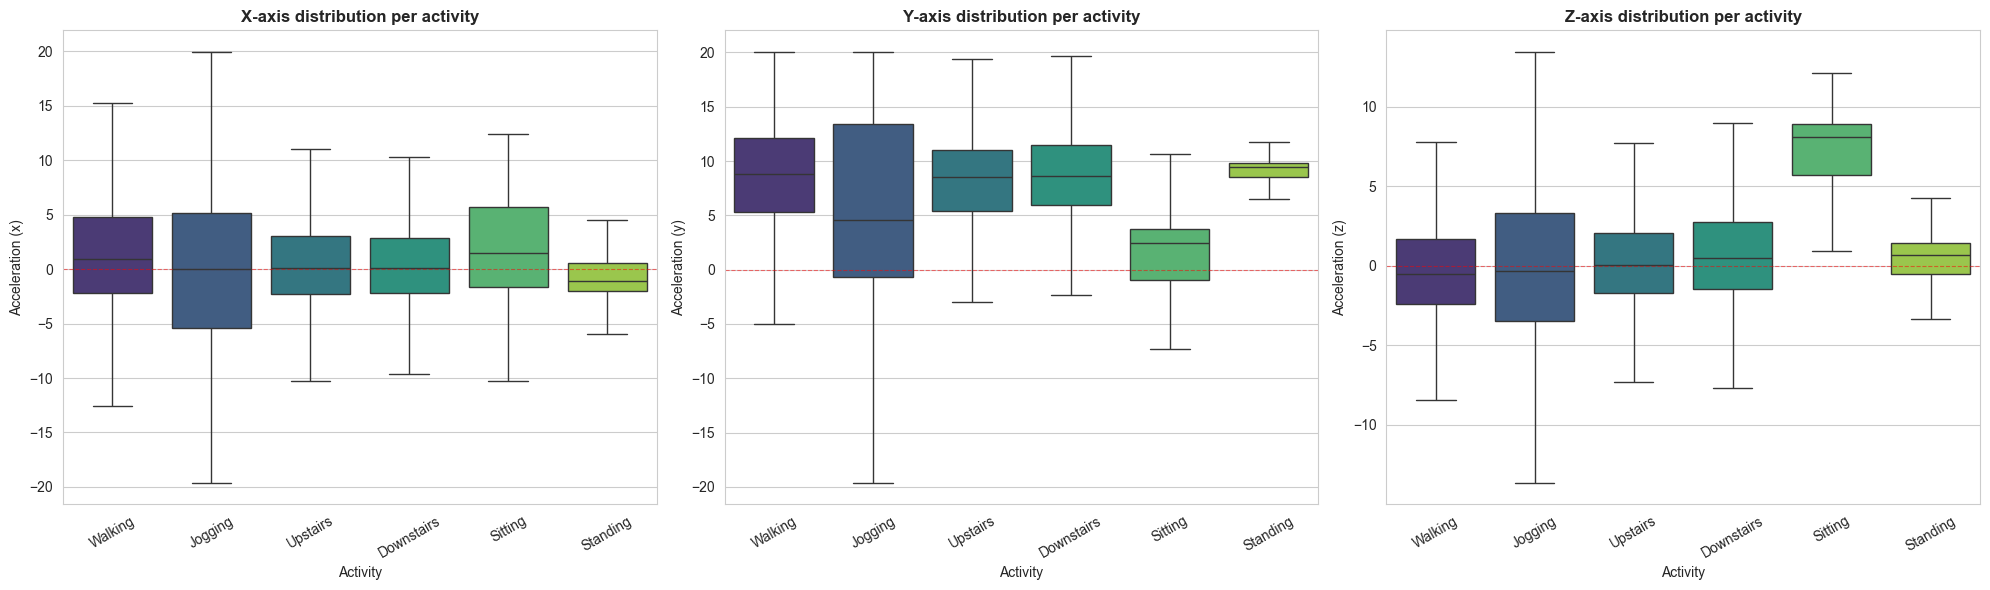

Outlier check (values beyond [-20, 20]):
  x: 0 values (0.0000%)
  y: 881 values (0.0802%)
  z: 0 values (0.0000%)


In [11]:
# Cell 11: Boxplots per Activity per Axis (Section 2-1)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

activity_order = ['Walking', 'Jogging', 'Upstairs', 'Downstairs', 'Sitting', 'Standing']

for ax, axis_name in zip(axes, ['x', 'y', 'z']):
    sns.boxplot(
        data=df, x='activity', y=axis_name,
        order=activity_order, ax=ax,
        palette='viridis', showfliers=False
    )
    ax.set_title(f'{axis_name.upper()}-axis distribution per activity', fontweight='bold')
    ax.set_xlabel('Activity')
    ax.set_ylabel(f'Acceleration ({axis_name})')
    ax.tick_params(axis='x', rotation=30)
    ax.axhline(0, color='red', linestyle='--', alpha=0.5, linewidth=0.8)

plt.tight_layout()
plt.show()

# Outlier check
print('Outlier check (values beyond [-20, 20]):')
for axis in ['x', 'y', 'z']:
    n_out = ((df[axis] < -20) | (df[axis] > 20)).sum()
    print(f'  {axis}: {n_out:,} values ({100*n_out/len(df):.4f}%)')

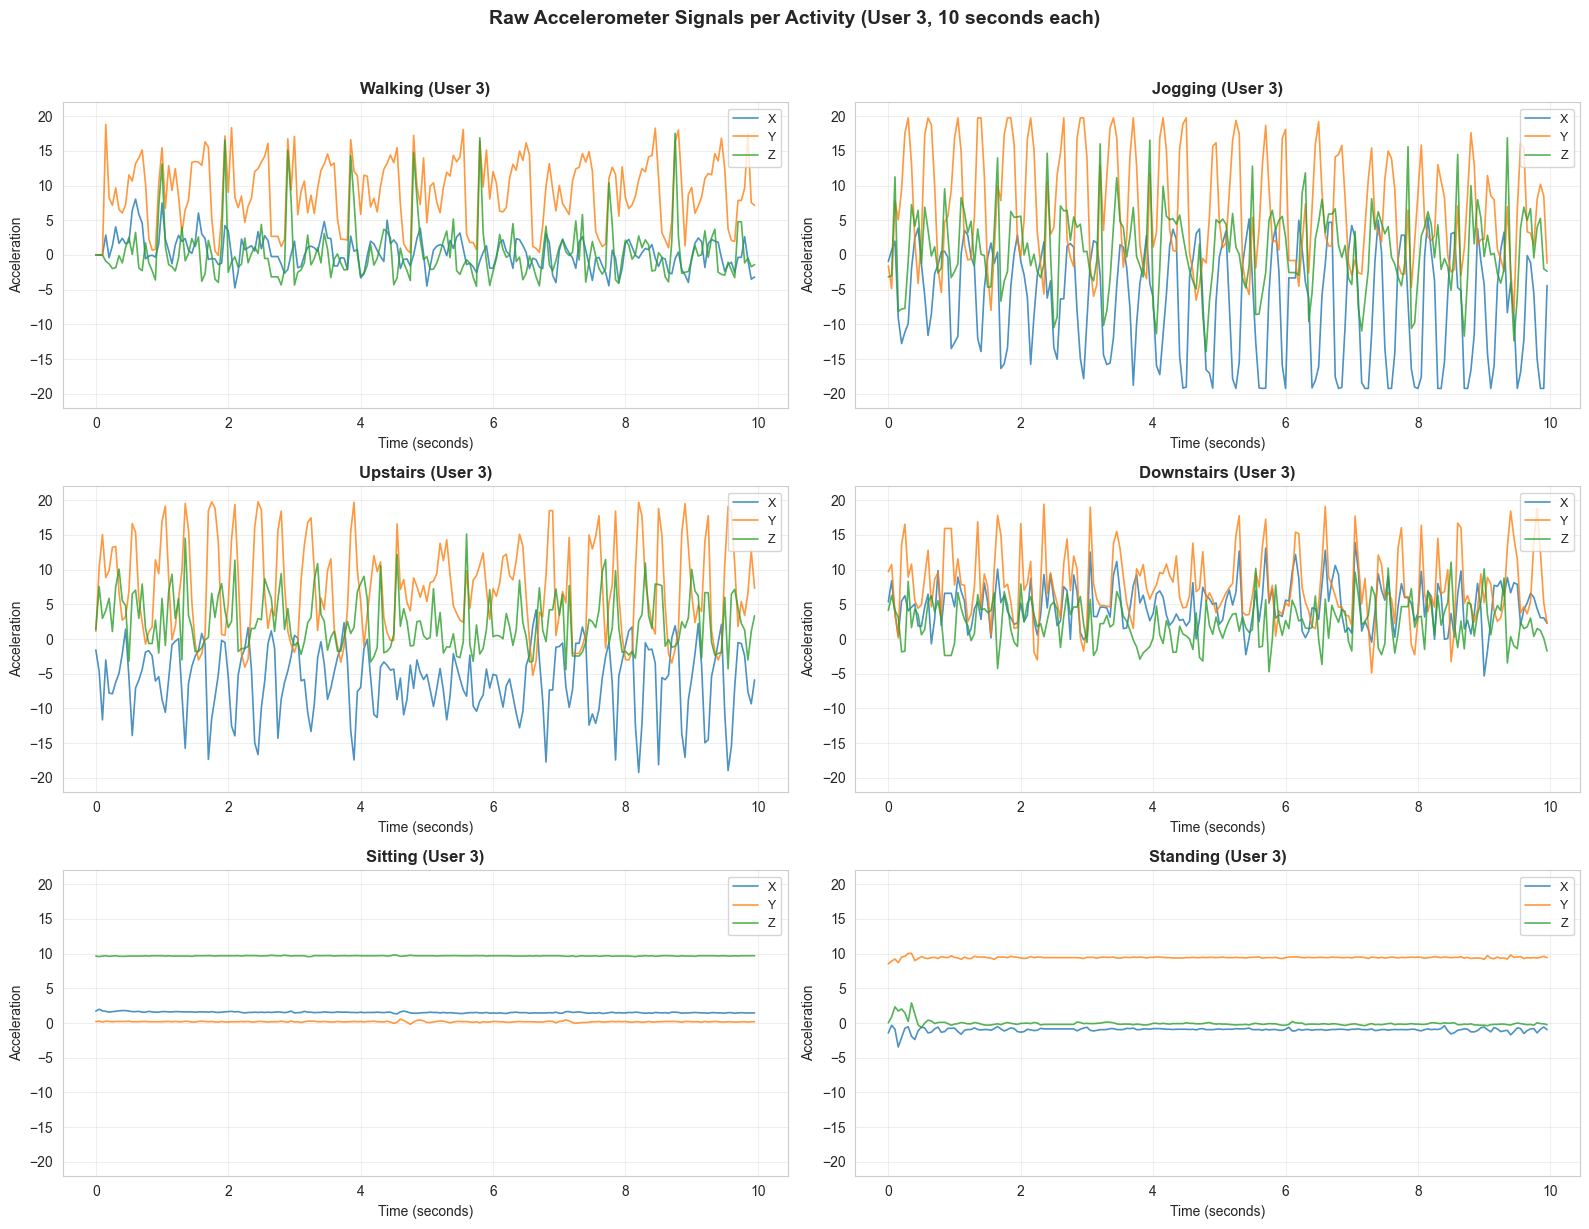

In [12]:
# Cell 12: Raw Signals per Activity (Section 2-2)

target_user = 3  # User 3 has almost all activities
activities = ['Walking', 'Jogging', 'Upstairs', 'Downstairs', 'Sitting', 'Standing']

fig, axes = plt.subplots(3, 2, figsize=(16, 12))
axes = axes.flatten()

for i, act in enumerate(activities):
    # Filter user & activity, sort by time, take first 200 samples (10s)
    subset = df[(df['user'] == target_user) & (df['activity'] == act)].sort_values('timestamp')
    subset = subset.iloc[:200].reset_index(drop=True)
    
    time_axis = np.arange(len(subset)) / 20.0  # 20 Hz sampling rate
    
    # Plot X, Y, Z
    axes[i].plot(time_axis, subset['x'], label='X', alpha=0.8, linewidth=1.2)
    axes[i].plot(time_axis, subset['y'], label='Y', alpha=0.8, linewidth=1.2)
    axes[i].plot(time_axis, subset['z'], label='Z', alpha=0.8, linewidth=1.2)
    
    axes[i].set_title(f'{act} (User {target_user})', fontweight='bold', fontsize=12)
    axes[i].set_xlabel('Time (seconds)')
    axes[i].set_ylabel('Acceleration')
    
    # CRITICAL: Same Y-axis scale for all subplots
    axes[i].set_ylim(-22, 22)
    
    axes[i].grid(True, alpha=0.3)
    axes[i].legend(loc='upper right', fontsize=9)

plt.suptitle(f'Raw Accelerometer Signals per Activity (User {target_user}, 10 seconds each)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

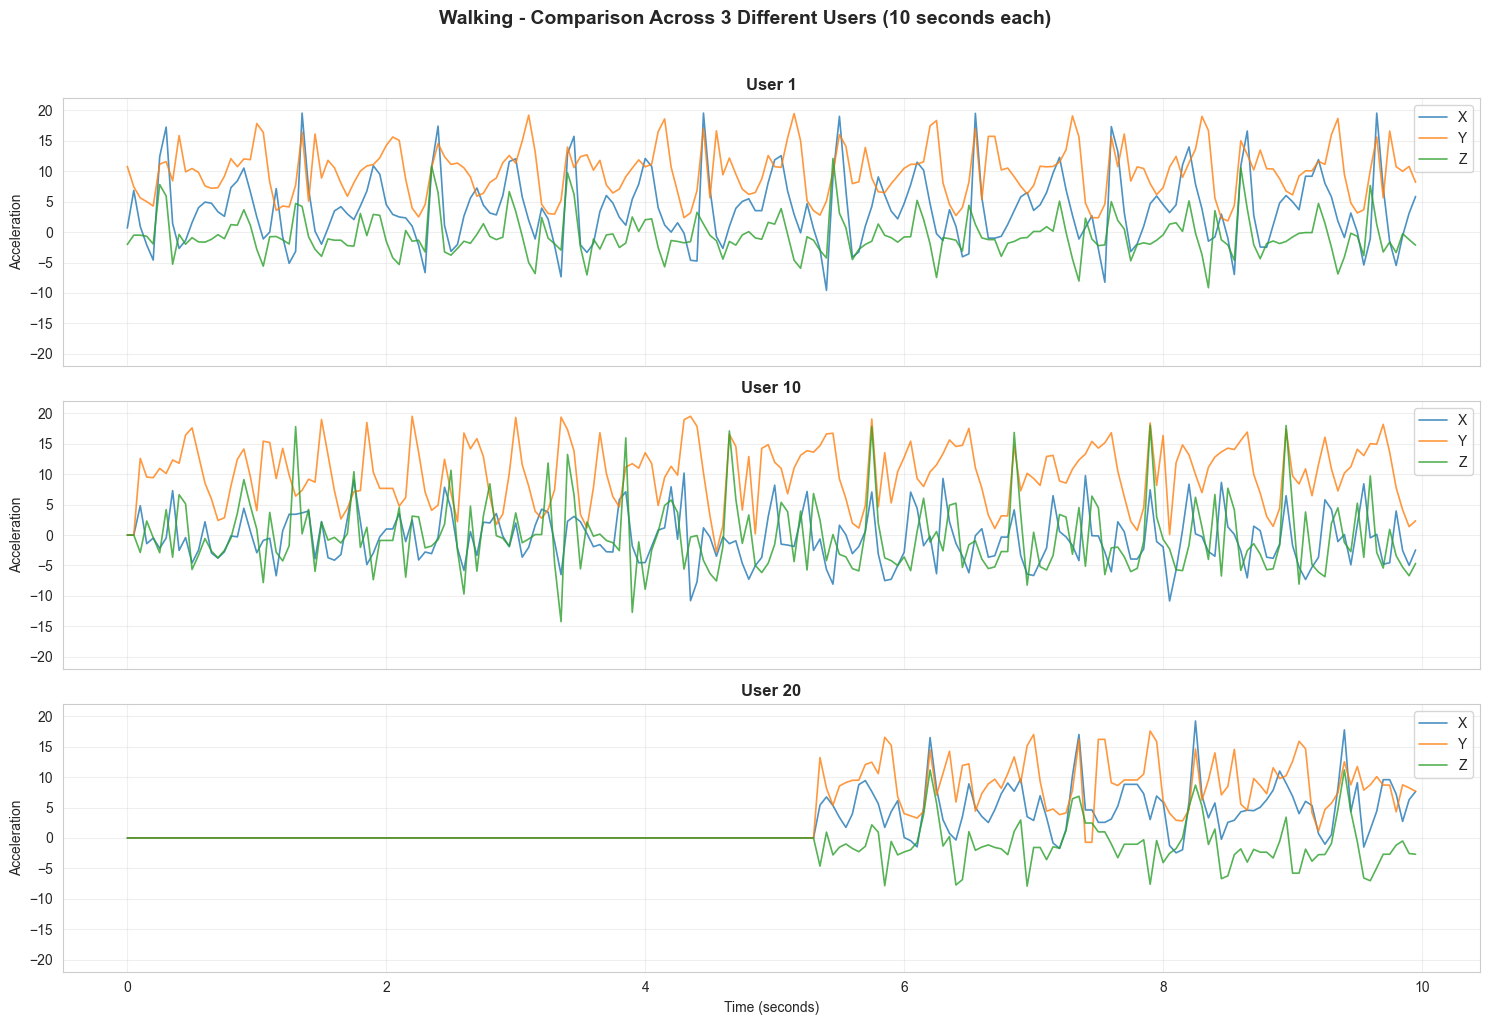

Statistics for Walking across users:


x              y              z       
        mean    std    mean    std    mean    std
user                                             
1    -1.0000 6.9680  9.4560 5.3960 -0.3440 3.2210
10   -1.4880 4.7090 10.3630 4.9580 -0.1460 5.3980
20    0.7720 5.5830  9.7060 4.5720  0.3060 4.2830

In [13]:
# Cell 13: Individual Differences in Walking (Section 2-3)

target_activity = 'Walking'
users_to_compare = [1, 10, 20]  # 3 different users

fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True, sharey=True)

for i, u in enumerate(users_to_compare):
    subset = df[(df['user'] == u) & (df['activity'] == target_activity)].sort_values('timestamp')
    subset = subset.iloc[:200].reset_index(drop=True)
    time_axis = np.arange(len(subset)) / 20.0
    
    axes[i].plot(time_axis, subset['x'], label='X', alpha=0.8, linewidth=1.2)
    axes[i].plot(time_axis, subset['y'], label='Y', alpha=0.8, linewidth=1.2)
    axes[i].plot(time_axis, subset['z'], label='Z', alpha=0.8, linewidth=1.2)
    
    axes[i].set_title(f'User {u}', fontweight='bold', fontsize=12)
    axes[i].set_ylabel('Acceleration')
    axes[i].set_ylim(-22, 22)  # Same scale
    axes[i].grid(True, alpha=0.3)
    axes[i].legend(loc='upper right')

axes[-1].set_xlabel('Time (seconds)')
plt.suptitle(f'{target_activity} - Comparison Across 3 Different Users (10 seconds each)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Also compute basic stats per user to back up visual observations
print(f'Statistics for {target_activity} across users:')
walk_stats = df[df['activity'] == target_activity].groupby('user')[['x', 'y', 'z']].agg(['mean', 'std'])
display(walk_stats.loc[users_to_compare].round(3))

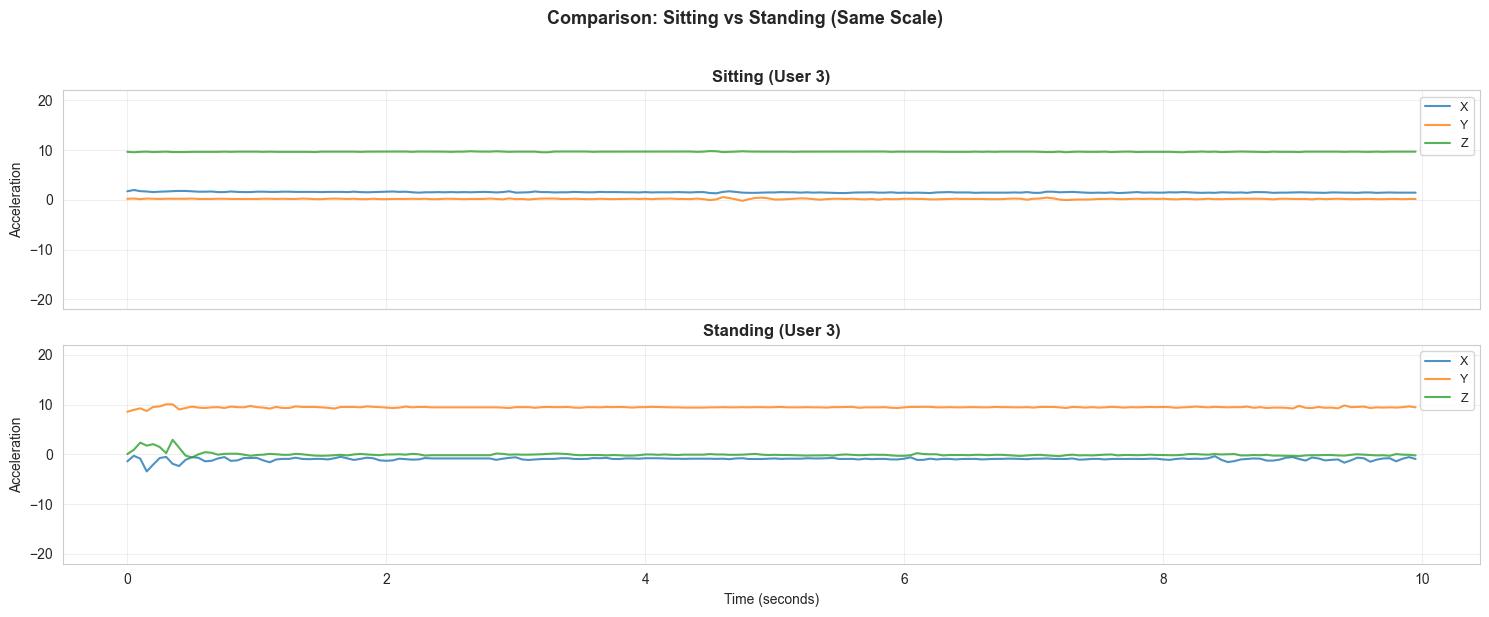

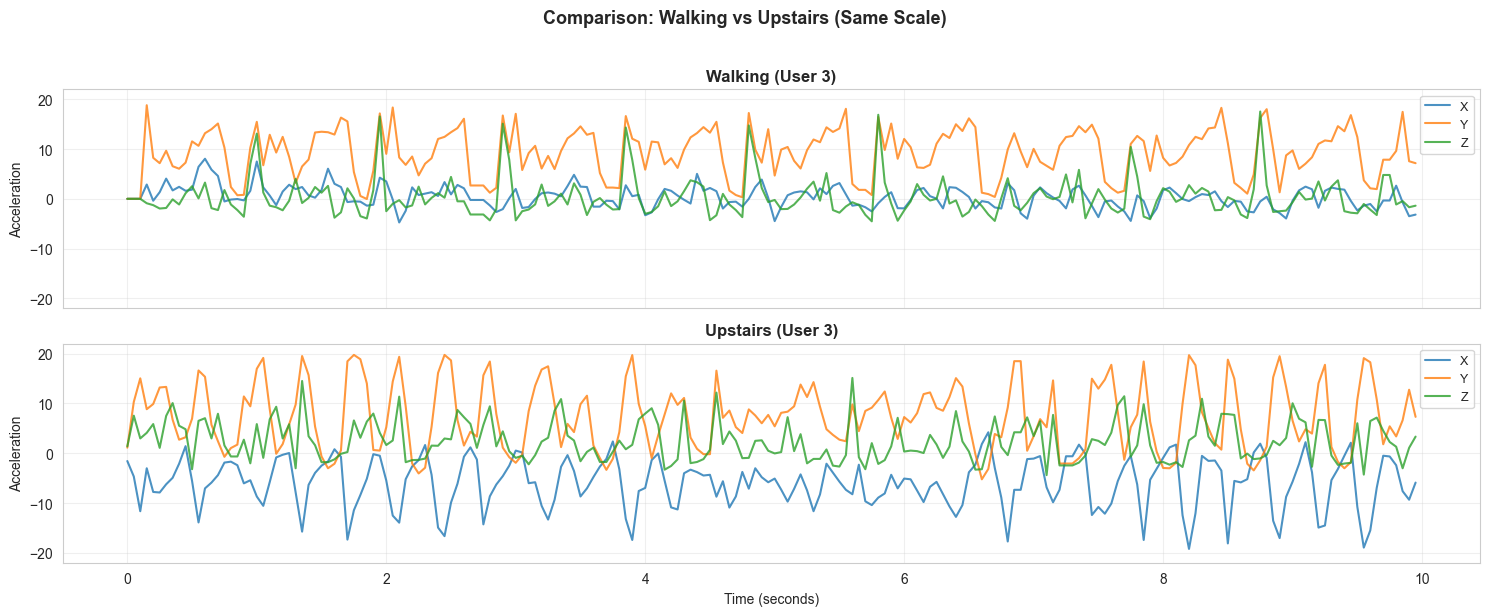

STATISTICS: Sitting vs Standing
               x             y             z       
            mean    std   mean    std   mean    std
activity                                           
Sitting   1.8560 4.7590 1.8530 3.2580 6.5600 3.7360
Standing -1.1780 3.2350 8.9870 1.2650 0.5800 1.3770

STATISTICS: Walking vs Upstairs
              x             y              z       
           mean    std   mean    std    mean    std
activity                                           
Upstairs 0.3810 5.4950 8.1120 4.8910  0.3240 3.5680
Walking  1.5280 5.7930 8.7020 5.0070 -0.0840 4.0110


In [14]:
# Cell 14: Similar Activities Comparison (Section 2-4)

target_user = 3

pairs = [
    ('Sitting', 'Standing'),
    ('Walking', 'Upstairs')
]

for act1, act2 in pairs:
    fig, axes = plt.subplots(2, 1, figsize=(15, 6), sharex=True, sharey=True)
    
    for i, act in enumerate([act1, act2]):
        subset = df[(df['user'] == target_user) & (df['activity'] == act)].sort_values('timestamp')
        subset = subset.iloc[:200].reset_index(drop=True)
        time_axis = np.arange(len(subset)) / 20.0
        
        axes[i].plot(time_axis, subset['x'], label='X', alpha=0.8)
        axes[i].plot(time_axis, subset['y'], label='Y', alpha=0.8)
        axes[i].plot(time_axis, subset['z'], label='Z', alpha=0.8)
        
        axes[i].set_title(f'{act} (User {target_user})', fontweight='bold')
        axes[i].set_ylabel('Acceleration')
        axes[i].set_ylim(-22, 22)
        axes[i].grid(True, alpha=0.3)
        axes[i].legend(loc='upper right', fontsize=9)
    
    axes[-1].set_xlabel('Time (seconds)')
    fig.suptitle(f'Comparison: {act1} vs {act2} (Same Scale)', 
                 fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# Stats
print('='*60)
print('STATISTICS: Sitting vs Standing')
print('='*60)
print(df[df['activity'].isin(['Sitting', 'Standing'])].groupby('activity')[['x', 'y', 'z']].agg(['mean', 'std']).round(3))

print('\n' + '='*60)
print('STATISTICS: Walking vs Upstairs')
print('='*60)
print(df[df['activity'].isin(['Walking', 'Upstairs'])].groupby('activity')[['x', 'y', 'z']].agg(['mean', 'std']).round(3))

PROPOSED FEATURES - EXAMPLE VALUES PER ACTIVITY


,Std(Z) [Variability],Mean Resultant [Magnitude],Mean Abs Dev(X) [Pattern]
Activity,,,
Walking,4.0110,11.4290,4.4580
Jogging,5.8330,13.4110,6.9760
Upstairs,3.5680,10.6970,3.9280
Downstairs,3.7070,10.8320,3.5780
Sitting,3.7360,9.8470,4.2070
Standing,1.3770,9.8150,2.2810


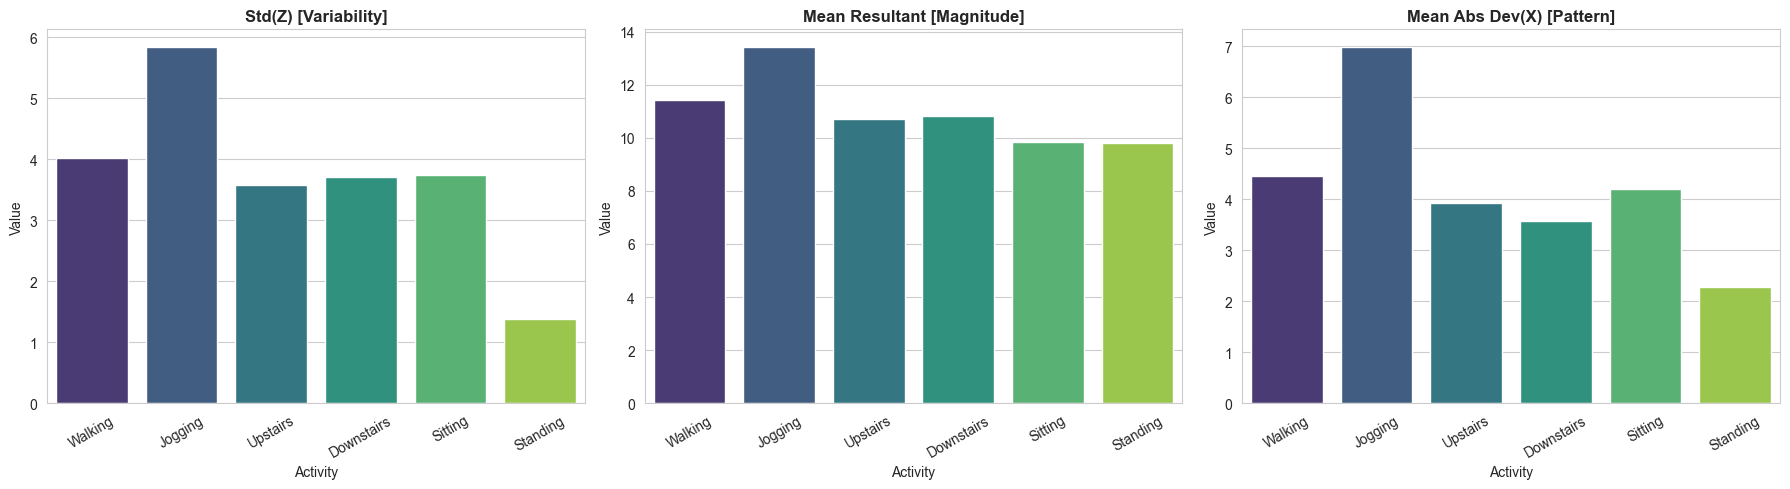

In [15]:
# Cell 15: Feature Proposal (Section 2-6)

# We compute examples of the proposed features to show they are meaningful
features_demo = []

for act in ['Walking', 'Jogging', 'Upstairs', 'Downstairs', 'Sitting', 'Standing']:
    subset = df[df['activity'] == act]
    
    # Feature 1: Standard deviation of Z (Signal variability)
    std_z = subset['z'].std()
    
    # Feature 2: Resultant magnitude mean (Combines all axes)
    resultant = np.sqrt(subset['x']**2 + subset['y']**2 + subset['z']**2)
    mean_resultant = resultant.mean()
    
    # Feature 3: Absolute deviation from mean in X (Gravity/static component)
    mean_abs_dev_x = (subset['x'] - subset['x'].mean()).abs().mean()
    
    features_demo.append({
        'Activity': act,
        'Std(Z) [Variability]': std_z,
        'Mean Resultant [Magnitude]': mean_resultant,
        'Mean Abs Dev(X) [Pattern]': mean_abs_dev_x
    })

features_df = pd.DataFrame(features_demo).set_index('Activity').round(3)

print('='*70)
print('PROPOSED FEATURES - EXAMPLE VALUES PER ACTIVITY')
print('='*70)
display(features_df)

# Plotting to show they separate activities well
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, features_df.columns):
    sns.barplot(x=features_df.index, y=features_df[col], ax=ax, palette='viridis')
    ax.set_title(col, fontweight='bold')
    ax.set_ylabel('Value')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()